# Exercise 01 — Workbook: your own protein

This notebook is **deliberately almost empty.** Its companion, **`ex01_guide.ipynb`**,
walks the entire analysis through on one protein (1FSZ, FtsZ) with every cell filled in.
Here you rebuild that analysis on a protein of **your own** choosing.

**Read `ex01_guide.ipynb` first.** Then work here, with it open beside you.

## How to work in this notebook

- **Copy code across from the guide and adapt it.** `rcsb_chain`,
  `search_pdb`, `structure_table`, and the alignment helpers
  `hmmer_search`, `align`, `drop_redundant` and `conservation` are all written to be
  generic: they work on any protein, not just 1FSZ. Reusing them is the point.
- **Structure the notebook however you like.** The section headers below are a checklist
  of what has to be here, not a cell-by-cell template. Add cells, split them, reorder
  them, delete these prompts once you've answered them.
- **The reasoning is what's graded, not the code.** Every section below asks for a
  written conclusion as well as output. A notebook full of correct plots with no
  interpretation scores badly; one with an honest, well-argued interpretation of a
  messy result scores well.

## Using AI Tools

You may use AI assistants (ChatGPT, Claude, etc.) for syntax, debugging, and code
snippets. You must supply the biological reasoning, the justification for your choices,
and the critical evaluation of what came back. **"The AI said so" is not an answer.**

**Note:** two prompts below (B-factor flexibility, and conserved regions) are
predict-first: you write your prediction down *before* you run anything. That written
prediction is the graded artefact. Being wrong costs you nothing; not having made a
prediction costs you the marks.

## Setup

Copy the guide's two setup cells here, the install cell and the imports cell, and run
them first. A Colab notebook starts empty, so nothing from the guide's session carries over.

In [ ]:
# Check if running on Google Colab
try:
    from google.colab import drive  # noqa: F401  (import is the availability test)
    is_google_colab = True
except ImportError:
    is_google_colab = False

# If on Google Colab, install the package
if is_google_colab:
    %pip install numpy==2.1.3 scipy==1.16.3 pandas==2.2.3 biopandas==0.4.1 py3dmol==2.4.0 biopython==1.85 pyfamsa==0.7.0 pymsaviz==0.5.0

# NOTE: Ignore specific warning message from ipykernel=5.5.6
import warnings
import os

In [5]:
# Import libraries
import gzip
import io
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from biopandas.pdb import PandasPdb
from Bio import SeqIO
from Bio.Align import MultipleSeqAlignment
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from pyfamsa import Aligner, Sequence
from pymsaviz import MsaViz
import py3Dmol


# Suppress all warnings at the Python level
warnings.filterwarnings('ignore')

# Also set environment variable to suppress warnings
os.environ['PYTHONWARNINGS'] = 'ignore'

# pandas draws through matplotlib by default -- df.plot() gives us a real Axes back,
# which keeps most plots in this notebook to two or three lines.
print("All libraries loaded successfully")

All libraries loaded successfully


---

## Character Sheet — your capstone protein

You **choose** your protein from the candidate list in `candidate_proteins.ipynb`, linked
from the README. **The ligand is not a choice**: each candidate is listed with the one
ligand that has already been run end to end with that protein, through molecular dynamics,
docking and a simulation of the two together. Pick a different het group out of the same
crystal and the later exercises will fail, or run and give you a meaningless number.

That pairing is the spine of the course: the same protein and ligand run through ex02
(AlphaFold), ex03 (molecular dynamics), ex04 (docking), and your final project. Choose one
you will be happy to live with for four days.

Record your choice:

- **PDB ID:**
- **Protein name:**
- **Organism:**
- **Method and resolution** (X-ray? NMR? cryo-EM? at what resolution?):
- **Ligand (CCD code and name):**


### Now catalogue *everything* in the structure

The candidate list names **one** ligand for your protein. Your structure almost certainly contains **more than
one** non-protein species, and telling them apart is the point of this section.

List **every** heteroatom species in your entry — the way the guide does for 1FSZ — with
how many atoms and how many copies of each. Then classify each one:

| Code | Name | Atoms | Copies | Biological, or experimental artifact? | Evidence |
|---|---|---|---|---|---|
| | | | | | |

**"Evidence" is the graded column.** For each species, say *how you decided*, using more
than one line of reasoning:

- What does the **RCSB entry page or the paper** say the structure was solved to study?
- **Where does it sit** — buried in a pocket making several contacts, or perched in a
  surface groove?
- Do you **recognise it as a lab reagent**? (glycerol, ethylene glycol, HEPES, MES, PEG,
  sulfate, acetate, DMSO…)
- Does it **recur in related structures** of the same protein, or appear only here?
- What do its **occupancy and B-factors** suggest about how well-ordered it is?

**Then find the binding site of your chosen ligand.**

**Look first.** `show_structure(your_pdb, ligand="XXX", pocket_of="XXX")` asks the viewer
itself for the residues within 4 Å of that species and labels them, using the same `within`
and `byres` selection PyMOL uses. Read them off the picture: how many are there, and what
kind are they? Polar, charged, hydrophobic, a recognisable motif?

> **What the pocket looks like:**

**Then type them out**, the way the guide does, as a plain list of residue names. A
binding site is short enough to type, and typing it is what makes you look at each residue
instead of at a number. Keep the list: ex03 and ex04 both build on it.

> **My ligand's contact residues:**

**If your structure is NMR**, there may be no heteroatoms at all, and there will be no
B-factors or occupancies — several rows of the table above will not apply. Say so
explicitly and explain what you can and cannot determine from an NMR ensemble. That is a
real, informative answer, not a failure to complete the task.

**If a species surprises you** — something you cannot classify either way — say so. "I
could not determine whether X is biological, and here is what I checked" is worth more
than a confident guess.

---

## Scientific Background

Rice blast disease is one of the most worldwide fungal infection by *Magnaporthe grisea*. Ariborne fungal spores spread on the surface of the leaves and start germinating. The appressorium then is heavily melanized which assists cell penetration under hydro static pressure. Non-pathogenic strains of *Magnaporthe grisea* lack the key enzyme in melanin synthesis, that is Scytalone dehydratase, rendering the formation of penetration peg¹⁻².

Scytalone dehydratase catalyzes melanin in two steps. Scytalone is converted to 1,3,8-trihydroxynaphthalene, and two steps later in the pathway, vermelone is converted to 1,8-dihydroxynaphthalene. Subsequently, the 1,8-dihydroxynaphthalene is polymerized into melanin. The enzyme requires no metal or cofactor. It is a trimer of three identical single-chain (single-domain) subunits. Each polypeptide chain consists of 170 amino acids and has a molecular weight of 23 kDa².

<center>

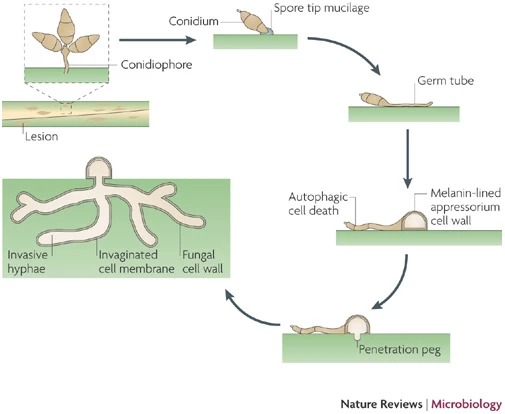]
</center>

1. Wilson, R., Talbot, N. Under pressure: investigating the biology of plant infection by Magnaporthe oryzae. Nat Rev Microbiol 7, 185–195 (2009). https://doi.org/10.1038/nrmicro2032
2. Lundqvist T, Rice J, Hodge CN, Basarab GS, Pierce J, Lindqvist Y. Crystal structure of scytalone dehydratase--a disease determinant of the rice pathogen, Magnaporthe grisea. Structure. 1994 Oct 15;2(10):937-44. doi: 10.1016/s0969-2126(94)00095-6. PMID: 7866745.

---

## 1STD, and every structure of its family

Start from the chain that binds your ligand (`rcsb_chain` gives its UniProt sequence),
list its family's structures (`search_pdb`, `structure_table`) and draw the guide's two
plots.

**Report:** how many structures, solved how? Where does *yours* sit: method, resolution
against the rest, R-free? You keep your structure: the point is knowing its strengths and
weaknesses.

In [12]:
# All the queries need for fetching protein information from RCSB and PDB
# Entry ID: 1STD
# Ligand: BFS
# Chain: A (auth_A), no auth_B or auth_C though protein has 3 chains
CHAIN_QUERY = """query($entry: String!, $chain: String!) {
  polymer_entity_instance(entry_id: $entry, asym_id: $chain) {
    rcsb_polymer_entity_instance_container_identifiers { auth_to_entity_poly_seq_mapping }
    rcsb_polymer_instance_feature { type name provenance_source
                                    feature_positions { beg_seq_id end_seq_id } }
    polymer_entity {
      rcsb_polymer_entity_feature { type name provenance_source
                                    feature_positions { beg_seq_id end_seq_id } }
      rcsb_polymer_entity_align { reference_database_name reference_database_accession
        aligned_regions { entity_beg_seq_id ref_beg_seq_id length } }
      uniprots { rcsb_id rcsb_uniprot_protein { sequence }
                 rcsb_uniprot_feature { type name feature_positions { beg_seq_id end_seq_id } } }
} } }"""

# The annotation types kept, and what each one is. RCSB serves many more (validation
# scores per residue, hydropathy, disorder predictions); these are the ones drawn here.
KINDS = {"CATH": "domain", "SCOP": "domain", "ECOD": "domain", "Pfam": "domain",
         "HELIX_P": "helix", "SHEET": "strand",
         "BINDING_SITE": "binding site", "ACTIVE_SITE": "active site"}


def rcsb_chain(pdb_id: str, chain: str = "A") -> tuple[str, str, pd.Series, pd.DataFrame]:
    """Everything RCSB knows about one chain, from one GraphQL request.

    Returns the UniProt accession, the UniProt sequence, `to_structure` (a Series from
    UniProt position to the residue number the file uses: the two often differ, through a
    tag, a construct that starts mid-protein or the authors' own scheme), and a table of
    annotations, one row per annotated residue: its source (CATH, SCOPe, ECOD, Pfam,
    PROMOTIF for secondary structure, PDB, UniProt), its kind (domain, helix, strand,
    binding site, active site), its name, and the residue in the file's numbering.
    `chain` is the chain ID as the file writes it.
    """
    answer = requests.post("https://data.rcsb.org/graphql", json={
        "query": CHAIN_QUERY, "variables": {"entry": pdb_id, "chain": chain}})
    found = answer.json()["data"]["polymer_entity_instance"]
    entity = found["polymer_entity"]
    # The file's residue number for each position of the chain's sequence (1, 2, 3, ...)
    author = found["rcsb_polymer_entity_instance_container_identifiers"][
        "auth_to_entity_poly_seq_mapping"]
    in_file = pd.Series([int(n) for n in author], index=range(1, len(author) + 1))

    uniprot = next(a for a in entity["rcsb_polymer_entity_align"]
                   if a["reference_database_name"] == "UniProt")
    accession = uniprot["reference_database_accession"]
    to_structure = pd.Series({
        region["ref_beg_seq_id"] + k: in_file[region["entity_beg_seq_id"] + k]
        for region in uniprot["aligned_regions"] for k in range(region["length"])})
    record = next(u for u in entity["uniprots"] if u["rcsb_id"] == accession)

    # Chain and entity annotations count in sequence positions, UniProt's in UniProt
    # positions: each is turned into the file's numbering with its own map.
    annotated = [(f, in_file) for f in (found["rcsb_polymer_instance_feature"] or [])
                 + (entity["rcsb_polymer_entity_feature"] or [])]
    annotated += [(f, to_structure) for f in record["rcsb_uniprot_feature"] or []]
    rows = []
    for feature, numbering in annotated:
        if feature["type"] not in KINDS:
            continue
        residues = [int(numbering[position])
                    for span in feature["feature_positions"] or []
                    for position in range(span["beg_seq_id"],
                                          (span["end_seq_id"] or span["beg_seq_id"]) + 1)
                    if position in numbering.index]  # a single residue has no end
        name = feature["name"] or ""
        if KINDS[feature["type"]] == "domain" and residues:  # two domains can share a name
            name = f"{name} ({min(residues)}-{max(residues)})"
        rows += [{"source": feature.get("provenance_source") or "UniProt",
                  "kind": KINDS[feature["type"]], "name": name, "residue": residue}
                 for residue in residues]
    return accession, record["rcsb_uniprot_protein"]["sequence"], to_structure, pd.DataFrame(rows)


def search_pdb(sequence: str, identity_cutoff: float = 0.3) -> list[str]:
    """Every PDB entry whose sequence matches `sequence`, best match first."""
    query = {"type": "terminal", "service": "sequence",
             "parameters": {"evalue_cutoff": 1, "identity_cutoff": identity_cutoff,
                            "target": "pdb_protein_sequence", "value": sequence}}
    response = requests.post(
        "https://search.rcsb.org/rcsbsearch/v2/query",
        json={"query": query, "return_type": "entry",
              "request_options": {"return_all_hits": True,
                                  "sort": [{"sort_by": "score", "direction": "desc"}]}},
    )
    response.raise_for_status()
    return [hit["identifier"] for hit in response.json().get("result_set", [])]


def structure_table(pdb_ids: list[str]) -> pd.DataFrame:
    """Method, resolution, R-free and deposition year for each entry, one row per entry.

    RCSB's Data API speaks GraphQL: one query names the fields wanted, and answers for
    hundreds of entries at once instead of one request each. Not every method reports
    every number: NMR has no resolution, cryo-EM no R-free, and an integrative model (built
    from several kinds of data) neither, so those come back empty.
    """
    query = """query($ids: [String!]!) { entries(entry_ids: $ids) {
      rcsb_id rcsb_entry_info { experimental_method resolution_combined }
      refine { ls_R_factor_R_free } rcsb_accession_info { deposit_date } } }"""
    entries = []
    for start in range(0, len(pdb_ids), 500):  # a few hundred per request keeps it quick
        answer = requests.post("https://data.rcsb.org/graphql", json={
            "query": query, "variables": {"ids": pdb_ids[start:start + 500]}})
        entries += answer.json()["data"]["entries"]
    return pd.DataFrame([{
        "pdb_id": e["rcsb_id"],
        "method": e["rcsb_entry_info"]["experimental_method"],
        "resolution": (e["rcsb_entry_info"]["resolution_combined"] or [None])[0],
        "r_free": (e["refine"] or [{}])[0].get("ls_R_factor_R_free"),
        "year": int(e["rcsb_accession_info"]["deposit_date"][:4]),
    } for e in entries])

In [15]:
accession, query, to_structure, features = rcsb_chain("1STD", "A")
pdb_ids = search_pdb(query)
family = structure_table(pdb_ids)

In [16]:
print(f"1STD chain A is UniProt {accession}, {len(query)} residues")
print(f"Structures of the family in the PDB: {len(family)}")
family.head()

1STD chain A is UniProt P56221, 172 residues
Structures of the family in the PDB: 11


,pdb_id,method,resolution,r_free,year
0,1STD,X-ray,2.90,NaN,1994
1,2STD,X-ray,2.10,0.259,1997
2,1IDP,X-ray,1.45,0.235,2001
3,3STD,X-ray,1.65,0.230,1998
4,4STD,X-ray,2.15,0.278,1999


### Where 1STD sits among them

In [17]:
print(family["method"].value_counts().to_string(), "\n")

mine = family.set_index("pdb_id").loc["1STD"]
xray = family.loc[family["method"] == "X-ray", "resolution"].dropna()
print(f"1STD: {mine['method']}, {mine['resolution']:.2f} Å, R-free {mine['r_free']:.3f}, "
      f"deposited {mine['year']}")
print(f"{(xray < mine['resolution']).sum()} of the family's {len(xray)} X-ray structures "
      f"are sharper; their median is {xray.median():.2f} Å")

method
X-ray    11 

1STD: X-ray, 2.90 Å, R-free nan, deposited 1994
10 of the family's 11 X-ray structures are sharper; their median is 1.80 Å


### How were they solved?

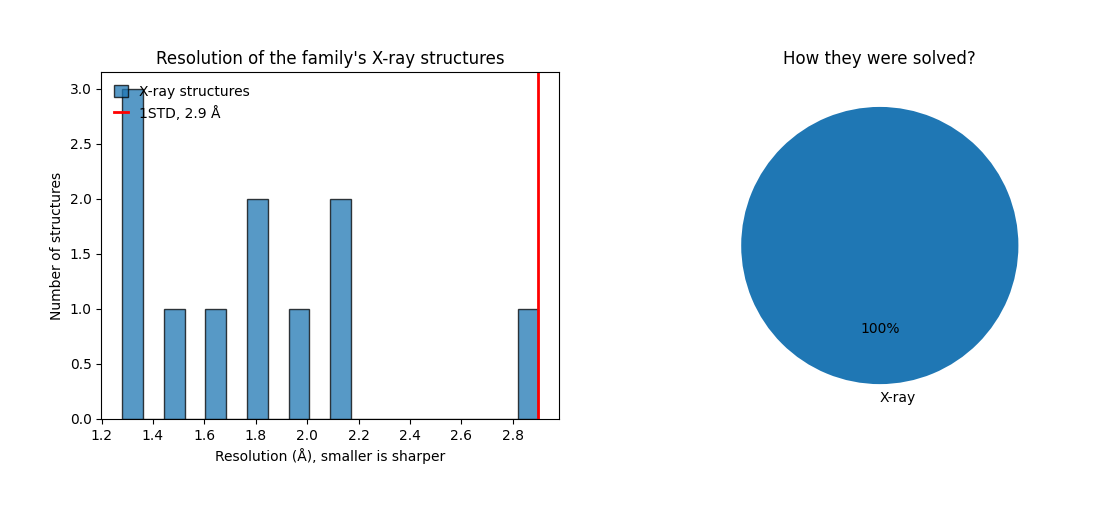

In [38]:
fig, (hist, pie) = plt.subplots(1, 2, figsize=(13, 4.5))

xray.plot.hist(ax=hist, bins=20, edgecolor="black", alpha=0.75, label="X-ray structures",
               title="Resolution of the family's X-ray structures")
hist.axvline(mine["resolution"], color="red", lw=2, label=f"1STD, {mine['resolution']:.1f} Å")
hist.set(xlabel="Resolution (Å), smaller is sharper", ylabel="Number of structures")
hist.legend()

family["method"].value_counts().plot.pie(ax=pie, autopct="%1.0f%%", startangle=90,
                                          title="How they were solved?")
pie.set_ylabel("")
plt.show()

---

### Structure of 1STD

Produce, with a sentence on what each one shows you:

- Your structure coloured by its annotations (from `rcsb_chain`): secondary
  structure, domains, and binding or active sites. Say whose each is (CATH, UniProt, ...);
  one domain is an answer too
- If your structure has a ligand: zoom in on it and its contacts, as the guide's GDP
  view does

You will come back to this section: once you have the alignment from section 4, you add a
**conserved-residue view** to this set.

The Scytalone dehydratase (1STD, chain/subunit A) monomer belongs to the α+β class of structure with 46+74 residues, respectively. It binds 2 different inhibitory ligands (1) BFS at the binding sites Y30, Y50, F53, N131 and (2) SO4 . This subunit has a single domain that spans 162 residues (position 9-170).
| Code | Atoms | What it is | Real, or experimental artifact? |
|---|---|---|---|
| `BFS` | 20, one copy |  N-[1-(4-bromophenyl)ethyl]-5-fluorosalicylamide | **the chemical inhibitor.** ²(Figure 1b, structure 7)  |
| `SO4` | 5, one copy |  sulfate ion | **co-crystallized ligand** in the surronding side chain of two subunits ² |
| `HOH` | 4, four copies | water | **solvent.** Never the answer to "what does this protein bind" |

In [21]:
def load_structure(pdb_id: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Protein atoms and heteroatoms for one entry, as two DataFrames."""
    ppdb = PandasPdb().fetch_pdb(pdb_id)
    return ppdb.df["ATOM"], ppdb.df["HETATM"]


def heteroatom_inventory(hetatms: pd.DataFrame) -> pd.DataFrame:
    """Every non-protein species in the file, with how many atoms and copies each has."""
    return (
        hetatms.groupby("residue_name")
        .agg(atoms=("atom_number", "size"), copies=("residue_number", "nunique"))
        .sort_values("atoms", ascending=False)
    )


def bfactor_profile(atoms: pd.DataFrame) -> pd.Series:
    """CA B-factors indexed by residue number.

    NaN wherever the crystal resolved nothing. Reindexing onto the full range is what
    makes matplotlib draw real gaps instead of joining a line straight across them.
    """
    ca = atoms[atoms["atom_name"] == "CA"]
    profile = (ca.set_index("residue_number")["b_factor"]
               .reindex(range(ca["residue_number"].min(), ca["residue_number"].max() + 1)))
    profile.index.name = "Residue number"
    return profile


def show_structure(pdb_id: str, color: str = "spectrum",
                   groups: dict[str, list[int]] | None = None,
                   highlight: list[int] | tuple[int, ...] = (),
                   ligand: str | None = None, pocket_of: str | None = None,
                   label_pocket: bool = True, radius: float = 4.0,
                   width: int = 800, height: int = 500) -> py3Dmol.view:
    """Cartoon view of an entry.

    `color` is "spectrum" (along the chain, N-terminus blue to C-terminus red) or
    "b-factor" (rigid blue to flexible red). `groups` names sets of residues, each drawn in
    its own colour on grey, with the key printed. `highlight` colours those residues red;
    `ligand` shows a heteroatom as sticks; `pocket_of` asks the viewer itself for the
    residues lining that heteroatom, with `within` and `byres`, the same two words PyMOL
    uses. `hetflag` keeps the ligand and the waters out of the answer.
    """
    view = py3Dmol.view(query=f"pdb:{pdb_id}", width=width, height=height)
    if color == "b-factor":
        # Colour between the 5th and 95th percentile, so a few extreme atoms do not
        # wash everything else out. The range runs high to low: 3Dmol's red-white-blue
        # gradient starts red at its first value.
        atoms, _ = load_structure(pdb_id)
        low, high = atoms["b_factor"].quantile([0.05, 0.95])
        view.setStyle({"cartoon": {"colorscheme": {
            "prop": "b", "gradient": "rwb", "min": high, "max": low}}})
    elif groups or len(highlight) or pocket_of:
        view.setStyle({"cartoon": {"color": "lightgrey"}})
    else:
        view.setStyle({"cartoon": {"color": "spectrum"}})
    palette = ["crimson", "gold", "royalblue", "seagreen", "darkorange", "purple"]
    for (name, residues), colour in zip((groups or {}).items(), palette):
        view.addStyle({"resi": list(residues)}, {"cartoon": {"color": colour}})
        print(f"{colour:>11}: {name} ({len(residues)} residues)")
    if len(highlight):
        view.addStyle({"resi": list(highlight)}, {"cartoon": {"color": "red"}})
        view.addStyle({"resi": list(highlight)}, {"stick": {"color": "red"}})
    if pocket_of:
        pocket = {"hetflag": False, "byres": True,
                  "within": {"distance": radius, "sel": {"resn": pocket_of}}}
        view.addStyle(pocket, {"stick": {"colorscheme": "redCarbon"}})
        if label_pocket:
            view.addResLabels(pocket, {"font": "Arial", "fontSize": 10,
                                       "fontColor": "black", "showBackground": False})
    if ligand:
        view.addStyle({"resn": ligand}, {"stick": {"colorscheme": "greenCarbon"}})
    if pocket_of:
        view.zoomTo({"resn": pocket_of})
    else:
        view.zoomTo()
    return view

In [22]:
# The structure we are studying, coloured from N-terminus (blue) to C-terminus (red).
show_structure("1STD").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [23]:
features.groupby(["kind", "source", "name"])["residue"].agg(["count", "min", "max"])

count  \
kind         source   name                                                   
active site  UniProt                                                     2   
binding site PDB      ligand BFS                                         9   
                      ligand SO4                                         5   
             UniProt                                                     4   
domain       CATH      (9-170)                                         162   
             ECOD     HSP90,HATPase_c_3 (9-155)                        147   
             Pfam     Scytalone dehydratase (Scytalone_dh) (10-169)    160   
             SCOPe    Scytalone dehydratase (1-172)                    172   
helix        PROMOTIF helix                                             46   
strand       PROMOTIF sheet                                             74   

                                                                     min  max  
kind         source   name                                                     
active site  UniProt                                                  85  110  
binding site PDB      ligand BFS                                      50  158  
                      ligand SO4                                     107  128  
             UniProt                                                  30  131  
domain       CATH      (9-170)                                         9  170  
             ECOD     HSP90,HATPase_c_3 (9-155)                        9  155  
             Pfam     Scytalone dehydratase (Scytalone_dh) (10-169)   10  169  
             SCOPe    Scytalone dehydratase (1-172)                    1  172  
helix        PROMOTIF helix                                           13  169  
strand       PROMOTIF sheet                                           42  148

In [25]:
shown = features[features["source"] == "PROMOTIF"]
kind = shown.groupby("kind")["residue"].apply(list)
show_structure("1STD", groups={"helix": kind["helix"], "strand": kind["strand"]}).show()

    crimson: helix (46 residues)
       gold: strand (74 residues)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [28]:
cath = features[features["source"] == "CATH"].groupby("name")["residue"].apply(list)
show_structure("1STD", groups=cath.to_dict(), ligand="GDP").show()

    crimson:  (9-170) (162 residues)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [39]:
features.query("source == 'UniProt' and kind == 'binding site'")["residue"].tolist()

[50, 53, 131, 30]

In [36]:
bfs = features.query("source == 'UniProt' and kind == 'binding site'")["residue"].tolist()
show_structure("1STD", highlight=gtp, ligand="BFS").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### What else is in the crystal? Cataloguing the heteroatoms


In [40]:
pdb_id = "1STD"
atoms_df, hetatms = load_structure(pdb_id)

inventory = heteroatom_inventory(hetatms)
print(f"Heteroatom species in {pdb_id}:\n")
print(inventory.to_string())

Heteroatom species in 1STD:

              atoms  copies
residue_name               
BFS              20       1
SO4               5       1
HOH               4       4


In [43]:
# Ask the viewer where the ligand sits. `within` picks the atoms closer than 4 Å to the
# GDP, `byres` widens each hit to its whole residue, and `hetflag: False` leaves the
# ligand itself and the waters out. PyMOL says the same thing in the same words.
show_structure("1STD", ligand="BFS", pocket_of="BFS", radius=4.0).show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [44]:
# Ask the viewer where the ligand sits. `within` picks the atoms closer than 4 Å to the
# GDP, `byres` widens each hit to its whole residue, and `hetflag: False` leaves the
# ligand itself and the waters out. PyMOL says the same thing in the same words.
show_structure("1STD", ligand="SO4", pocket_of="SO4", radius=4.0).show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [54]:
# Seventeen labels, read off the view above and typed out. That is the whole method: a
# binding site is short enough to type, and typing it makes you look at each residue
# instead of at a number. Notice they come in four stretches that are far apart in the
# sequence and adjacent in space.
contacts = ["TYR50", "LEU76", "TYR30", "PHE162", "LEU147", "PRO149", "ASN131", "ILE151",
            "ILE151", "LEU106", "SER129", "PHE158", "HIS110", "VAL108", "ALA127"]

contact_resids = [int(name[3:]) for name in contacts]   # the numbers, for the comparison below

print(f"{len(contacts)} residues line the BFS:\n{', '.join(contacts)}")

15 residues line the BFS:
TYR50, LEU76, TYR30, PHE162, LEU147, PRO149, ASN131, ILE151, ILE151, LEU106, SER129, PHE158, HIS110, VAL108, ALA127


---

## 3. B-factor analysis: predict first

**Before you run anything:** write your prediction here. Which region of your protein do
you expect to be most flexible, and *why*? Base it on the biology: annotated
sites, domains, termini, loops.

> **My prediction:** GLU93 - VAL100 side chain (close to N terminus in the folding space)
>
> **My reasoning:** B-factor is a measure that identifies the flexibility of atoms, side chains, or even whole regions which are crucial in enzymes and in proteins in general. Low B-factor indicates well-ordered structure (e.g α helix and β sheet) in which atom motion is rather low. Moderate and High B-factor demonstrate higher degree of freedom of movement, i.e more flexibility (e.g intrinsic disorder, side chain). High B-factor is usually observed in low-resolution structure, typically longer loops have higher flexibility than shorter ones. Moreover, residues that hold BFS should possess low B-factor. The area away from BFS-contacted list should be more flexible.

Then plot the B-factors, colour your structure by them, and compare. Were you right? What does the actual pattern
tell you biologically? An honest "I was wrong, and here's what I think I missed" is worth
full marks.

My prediction was wrong. Since most of the residues in the pocket accumulate at C terminus, I expected that it would be more rigid in that region; however, the highest peak is around the C-terminus proximal region in folding space (M118 - T122).

Residue range: 9 to 170
Present: 162   Missing: 0

B-factor: mean 6.1, min 2.0, max 28.5 A^2
BFS-binding residues: mean 5.0 A^2, and 2 of 4 below the protein's mean


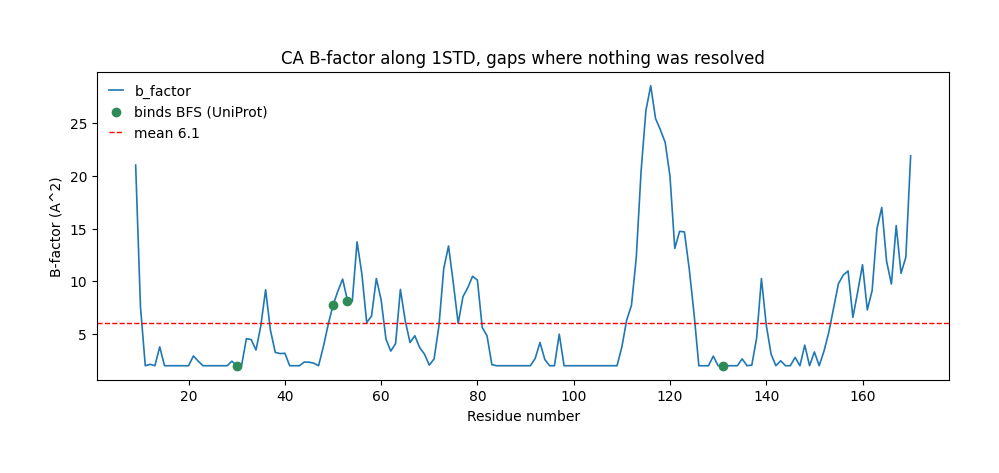

In [56]:
bfactors = bfactor_profile(atoms_df)
print(f"Residue range: {bfactors.index.min()} to {bfactors.index.max()}")
print(f"Present: {bfactors.notna().sum()}   Missing: {bfactors.isna().sum()}")
print(f"\nB-factor: mean {bfactors.mean():.1f}, min {bfactors.min():.1f}, "
      f"max {bfactors.max():.1f} A^2")
print(f"BFS-binding residues: mean {bfactors[gtp].mean():.1f} A^2, and "
      f"{(bfactors[gtp] < bfactors.mean()).sum()} of {len(gtp)} below the protein's mean")

ax = bfactors.plot(figsize=(11, 4), lw=1.2,
                   title=f"CA B-factor along {pdb_id}, gaps where nothing was resolved")
ax.scatter(gtp, bfactors[gtp], color="seagreen", zorder=3, label="binds BFS (UniProt)")
ax.set_ylabel("B-factor (A^2)")
ax.axhline(bfactors.mean(), color="red", ls="--", lw=1, label=f"mean {bfactors.mean():.1f}")
ax.legend()
plt.show()

**What this confirms:** the four BFS-binding residues average about 5 Å², against about 6.1 Å² for the rest of the protein, and two of four are below the protein's mean. The profile has **no internal gaps**, and 8 unresolved residues (1-8 at N-terminus) lie entirely outside the plotted range

The same numbers on the structure, from rigid blue to flexible red:

In [58]:
show_structure("1STD", color="b-factor", ligand="GDP").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

---

## 4. Multiple sequence alignment, and conservation on the structure (required)

Build an alignment, then **put its result back onto your 3D structure**.

**Step 1: build the alignment**, the way the guide does. Take your protein's UniProt
sequence from section 1, find its relatives in Swiss-Prot (`hmmer_search`), align the full sequences (`align`), and
keep one representative per 95% group (`drop_redundant`). Report how many relatives came
back and how many are left. Read their names: one family, or a superfamily, the way FtsZ
reaches tubulin? Keep distant relatives, and say what they are.

**Step 2: predict first, then compute.** Where do you *expect* conservation to cluster: an
active site, a ligand pocket, an interface? Write it down before computing anything.

> **My prediction:**

Then compute conservation (`conservation`) and move it onto your structure's own residue
numbers with the mapping from section 1. Call the most conserved 10% of your
modelled residues conserved, and report the cutoff value that gives.

**Step 3: put it on the structure.** Required: render the conserved residues with your
ligand in the same view, as the guide does for 1FSZ and its GDP, and add that view to your
section 2 figures.

**Step 4: interpret, against a baseline.** Report three numbers: how many of your
ligand's contact residues (from the Character Sheet) are conserved, how many chance would
give (10% of them), and the ratio. On 1FSZ: 8 of 17 against about 2. Matching chance is a
real finding too. Look at the alignment itself (`show_alignment`) as well. For each contact that misses the cutoff, is it a *gap* or a *different
amino acid*? Does conservation coincide with the rigid regions from section 3?

**Judge your own alignment.** Few relatives (under about ten after grouping) make almost
every column look conserved. If that is your case, say so, and weigh your numbers
accordingly.

**Timing:** seconds for the search on EBI's servers, a few more to download and align.

---

## Before you submit

- [ ] Character Sheet filled in (PDB ID, name, organism, why, open question)
- [ ] Both **predictions written before** their analyses (the B-factor prediction in
      section 3, the conservation prediction in section 4)
- [ ] **Conserved residues rendered on your structure**, added to your section 2 figures
- [ ] The **three conservation numbers**: observed, expected by chance, ratio
- [ ] Every section has a **written interpretation**, not just output
- [ ] Domain boundaries and any external claims are **cited**
- [ ] Anything that didn't work is **described honestly** rather than deleted — a
      documented dead end earns marks, a silently missing section does not